# GeoRisk AI — EDA, sensibilidad y evaluación de modelos

**Integrante 3 · CRISP-DM · Dataset sintético de 10.000 registros**

Este análisis compara Árbol de Decisión y Regresión Logística para predecir `deslizamiento_ocurrido`. Los resultados describen únicamente datos sintéticos y no son alertas validadas en terreno.

**Control de fuga:** se excluyen `id_registro`, `score_riesgo_bruto` y `indice_riesgo_deslizamiento`. El score y el índice se usaron para generar el objetivo. La partición estratificada 80/20 (`random_state=42`) ocurre antes de ajustar preprocesadores. Imputación, codificación y escalado viven dentro de pipelines ajustados solo con entrenamiento; la validación cruzada usa únicamente el conjunto de entrenamiento.

In [1]:
from pathlib import Path
import subprocess
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (StratifiedKFold, cross_validate,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
TARGET = 'deslizamiento_ocurrido'
VARS_NUM = ['precipitacion_24h_mm', 'precipitacion_3d_mm',
            'precipitacion_7d_mm', 'pendiente_grados', 'elevacion_m', 'humedad_pct']
VARS_CAT = ['departamento', 'tipo_suelo', 'geologia']
VARS_EXCLUIDAS = ['id_registro', 'score_riesgo_bruto', 'indice_riesgo_deslizamiento']
sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)

candidatos_raiz = [Path.cwd(), *Path.cwd().parents]
raiz = next((p for p in candidatos_raiz
             if (p / 'Dataset_10000_Bolivia_Sintetico.py').is_file()), None)
if raiz is None:
    raise FileNotFoundError('No se encontró Dataset_10000_Bolivia_Sintetico.py en el directorio actual ni sus padres.')
ruta_dataset = raiz / 'Dataset_10000_Bolivia_Sintetico.csv'
if not ruta_dataset.exists():
    subprocess.run([sys.executable, str(raiz / 'Dataset_10000_Bolivia_Sintetico.py')],
                   cwd=raiz, check=True)
df = pd.read_csv(ruta_dataset)
print(f'Dataset: {ruta_dataset}\nDimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')

Dataset: /workspaces/teletubis/Dataset_10000_Bolivia_Sintetico.csv
Dimensiones: 10,000 filas × 13 columnas


## 1. Comprensión de datos y calidad

Se comprueban esquema, faltantes, duplicados, clases y límites físicos básicos. También se reporta la coherencia entre acumulados de lluvia; el generador muestrea ventanas temporales de manera independiente, por lo que se conserva el dato y se documenta la limitación en vez de corregirlo silenciosamente.

In [2]:
assert len(df) == 10_000, f'Se esperaban 10.000 filas; se encontraron {len(df)}.'
assert TARGET in df.columns and set(df[TARGET].dropna().unique()) <= {0, 1}
calidad = pd.DataFrame({
    'medición': ['filas', 'columnas', 'nulos totales', 'filas duplicadas',
                 'precipitación 24h > 3d', 'precipitación 3d > 7d'],
    'valor': [len(df), df.shape[1], int(df.isna().sum().sum()),
              int(df.duplicated().sum()),
              int((df.precipitacion_24h_mm > df.precipitacion_3d_mm).sum()),
              int((df.precipitacion_3d_mm > df.precipitacion_7d_mm).sum())]
})
display(calidad)
balance = df[TARGET].value_counts().reindex([0, 1], fill_value=0).rename_axis('clase').to_frame('registros')
balance['porcentaje'] = balance.registros / len(df) * 100
balance.index = ['No ocurre (0)', 'Ocurre (1)']
display(balance.round(2))
display(df.dtypes.rename('tipo').to_frame())

rangos = []
for variable, minimo, maximo in [
    ('precipitacion_24h_mm', 0, np.inf), ('precipitacion_3d_mm', 0, np.inf),
    ('precipitacion_7d_mm', 0, np.inf), ('pendiente_grados', 0, 90),
    ('humedad_pct', 0, 100), ('elevacion_m', 500, 5000)]:
    fuera = (df[variable] < minimo) | (df[variable] > maximo)
    rangos.append({'variable': variable, 'mínimo observado': df[variable].min(),
                   'máximo observado': df[variable].max(), 'fuera de rango': int(fuera.sum())})
display(pd.DataFrame(rangos).round(2))

,medición,valor
0,filas,10000
1,columnas,13
2,nulos totales,0
3,filas duplicadas,0
4,precipitación 24h > 3d,2532
5,precipitación 3d > 7d,2449


,registros,porcentaje
No ocurre (0),5618,56.18
Ocurre (1),4382,43.82


,tipo
id_registro,int64
departamento,str
precipitacion_24h_mm,float64
precipitacion_3d_mm,float64
precipitacion_7d_mm,float64
pendiente_grados,float64
elevacion_m,float64
humedad_pct,float64
tipo_suelo,str
geologia,str


,variable,mínimo observado,máximo observado,fuera de rango
0,precipitacion_24h_mm,0.00,137.09,0
1,precipitacion_3d_mm,0.00,410.61,0
2,precipitacion_7d_mm,0.00,2066.28,0
3,pendiente_grados,0.00,82.13,0
4,humedad_pct,0.00,100.00,0
5,elevacion_m,500.21,4999.53,0


## 2. Análisis exploratorio de datos (EDA)

Las distribuciones se muestran por clase objetivo. Se usan escalas logarítmicas donde las colas de precipitación impiden apreciar el grueso de los datos. Las asociaciones exploratorias con el objetivo no implican causalidad ni se usan para seleccionar observaciones.

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
precipitacion_24h_mm,10000.0,14.99,14.93,0.00,4.45,10.45,20.59,34.22,45.07,68.84,137.09
precipitacion_3d_mm,10000.0,44.95,44.93,0.00,12.85,31.01,62.37,104.16,134.79,205.22,410.61
precipitacion_7d_mm,10000.0,179.73,215.52,0.00,40.15,98.12,217.26,528.67,645.48,945.28,2066.28
pendiente_grados,10000.0,30.36,14.83,0.00,20.15,30.17,40.34,49.83,55.11,65.52,82.13
elevacion_m,10000.0,2761.38,1304.35,500.21,1638.14,2744.14,3911.88,4562.62,4794.51,4956.44,4999.53
humedad_pct,10000.0,59.64,19.51,0.00,46.43,59.50,73.27,85.29,92.57,100.00,100.00


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
departamento,10000,6,Cochabamba,1692,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_suelo,10000,4,Limoso,2550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geologia,10000,3,Sedimentaria,3339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
deslizamiento_ocurrido,10000.0,NaN,NaN,NaN,0.4382,0.496191,0.0,0.0,0.0,1.0,1.0


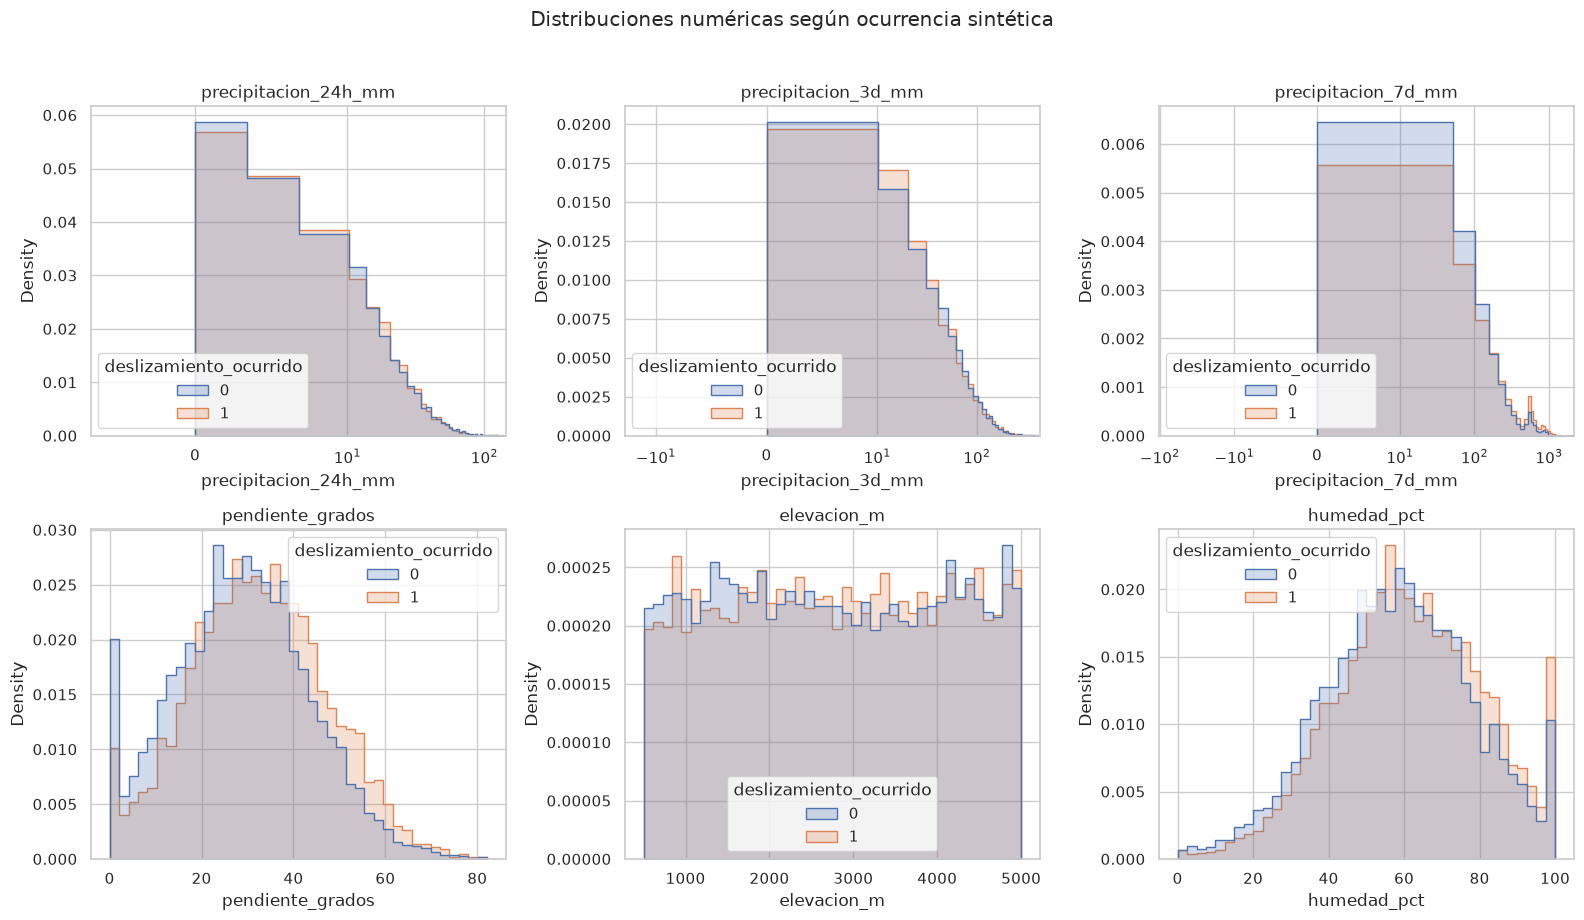

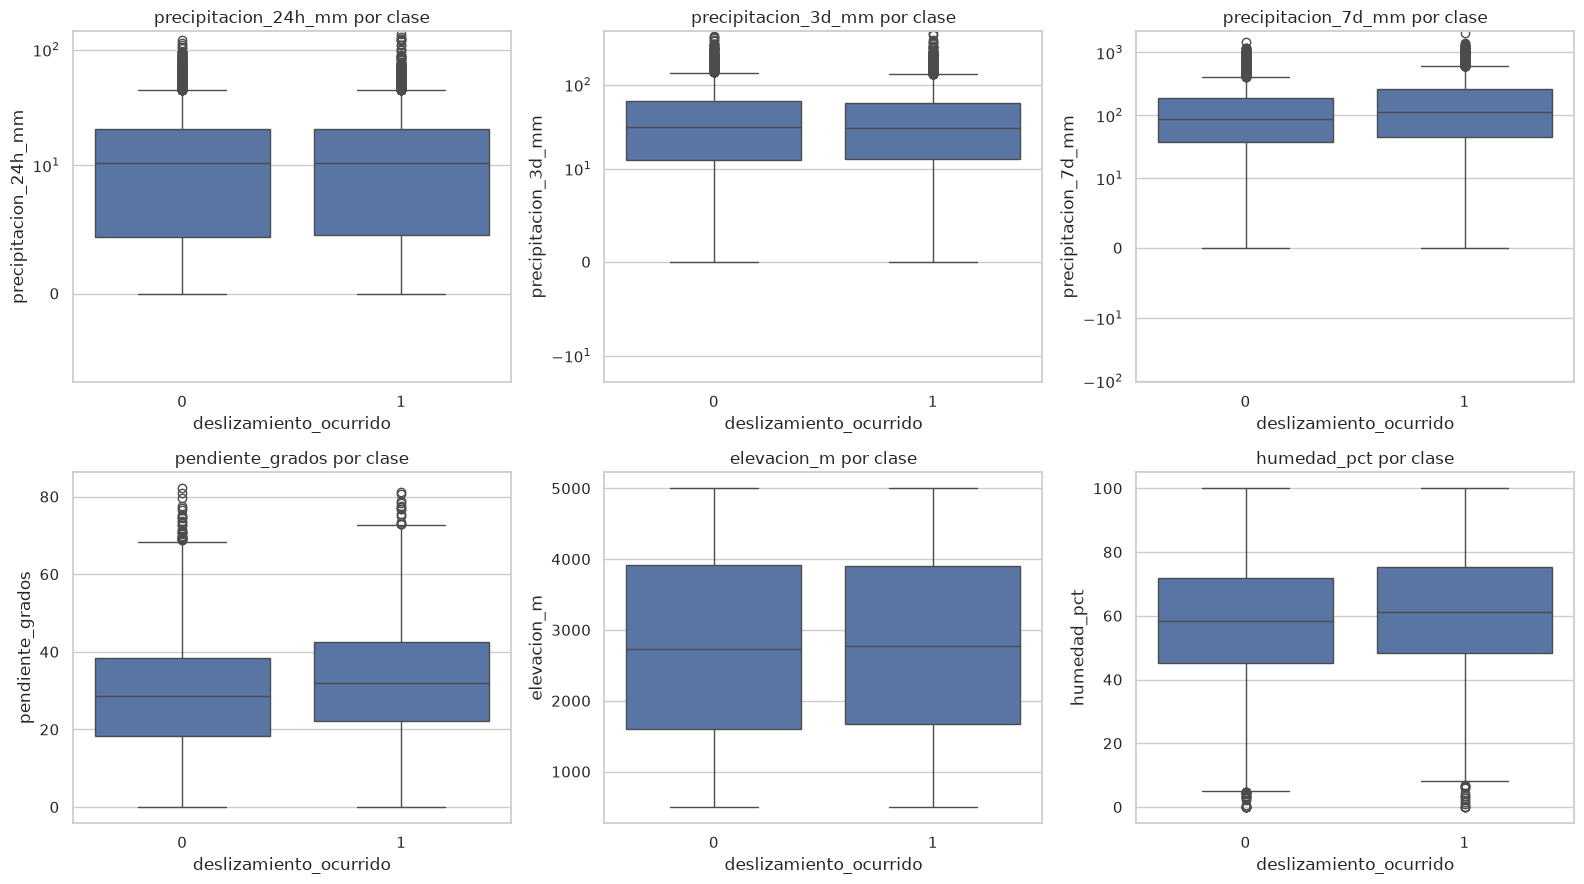

,categoría,registros,variable,tasa_pct
0,Chuquisaca,1625,departamento,43.51
1,Cochabamba,1692,departamento,44.92
2,La Paz,1665,departamento,43.54
3,Oruro,1689,departamento,43.52
4,Potosi,1657,departamento,43.63
5,Tarija,1672,departamento,43.78
6,Arcilloso,2445,tipo_suelo,45.40
7,Arenoso,2508,tipo_suelo,42.98
8,Franco,2497,tipo_suelo,43.17
9,Limoso,2550,tipo_suelo,43.76


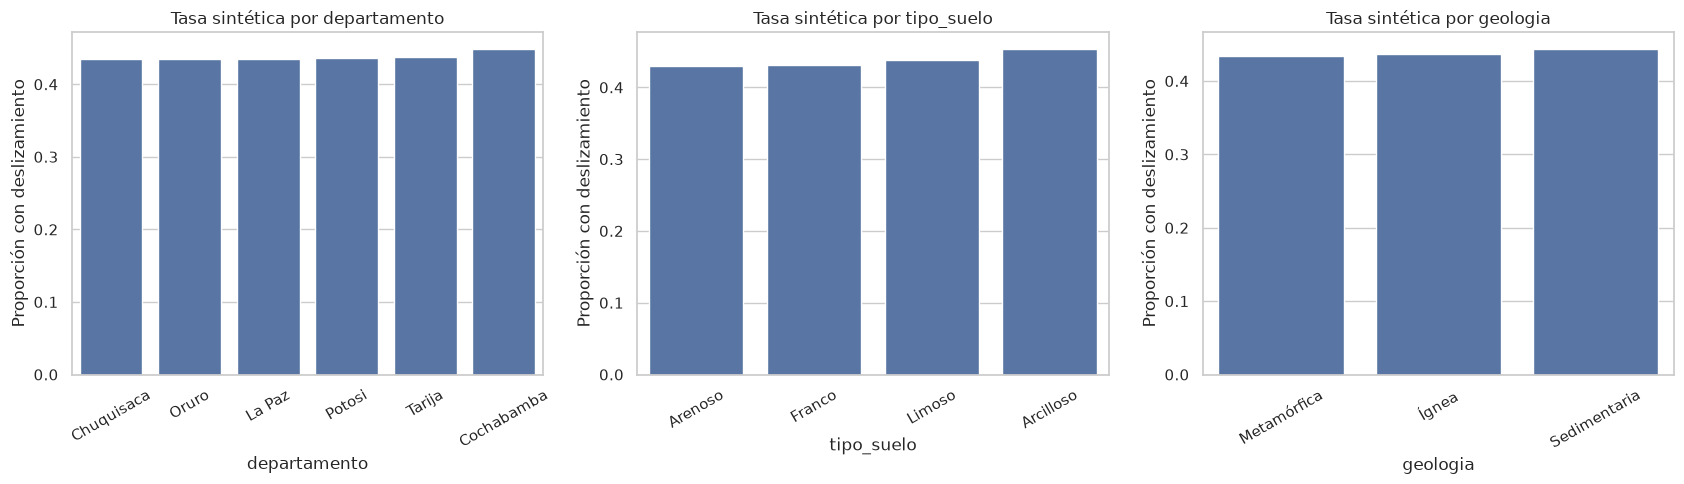

In [3]:
display(df[VARS_NUM].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T.round(2))
display(df[VARS_CAT + [TARGET]].describe(include='all').T)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, variable in zip(axes.flat, VARS_NUM):
    sns.histplot(data=df, x=variable, hue=TARGET, bins=40, stat='density',
                 common_norm=False, element='step', ax=ax)
    ax.set_title(variable)
    if variable.startswith('precipitacion_'):
        ax.set_xscale('symlog', linthresh=10)
plt.suptitle('Distribuciones numéricas según ocurrencia sintética', y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, variable in zip(axes.flat, VARS_NUM):
    sns.boxplot(data=df, x=TARGET, y=variable, ax=ax)
    ax.set_title(f'{variable} por clase')
    if variable.startswith('precipitacion_'):
        ax.set_yscale('symlog', linthresh=10)
plt.tight_layout()
plt.show()

tasas_cat = []
for variable in VARS_CAT:
    tmp = df.groupby(variable, observed=False)[TARGET].agg(['size', 'mean']).reset_index()
    tmp['variable'] = variable
    tmp = tmp.rename(columns={variable: 'categoría', 'size': 'registros', 'mean': 'tasa_objetivo'})
    tasas_cat.append(tmp)
tasas_cat = pd.concat(tasas_cat, ignore_index=True)
display(tasas_cat.assign(tasa_pct=tasas_cat.tasa_objetivo * 100).drop(columns='tasa_objetivo').round(2))
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, variable in zip(axes, VARS_CAT):
    orden = df.groupby(variable, observed=False)[TARGET].mean().sort_values().index
    sns.barplot(data=df, x=variable, y=TARGET, order=orden, errorbar=None, ax=ax)
    ax.set_title(f'Tasa sintética por {variable}')
    ax.set_ylabel('Proporción con deslizamiento')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

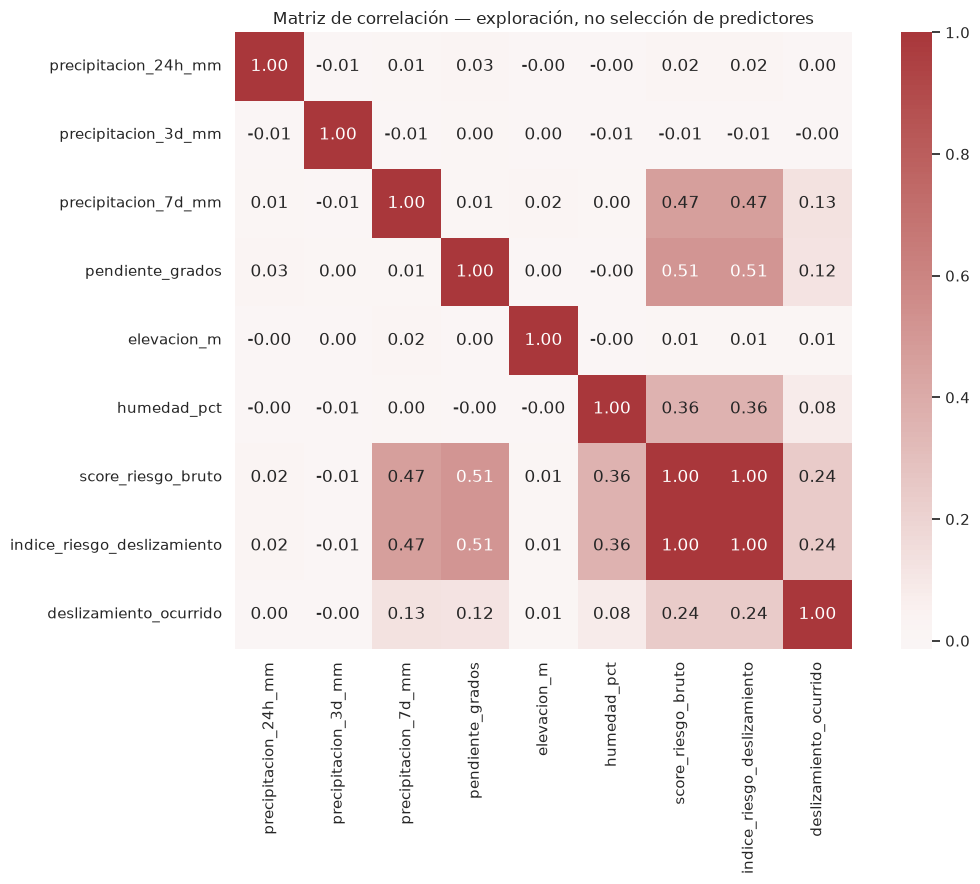

,correlación con objetivo
score_riesgo_bruto,0.240
indice_riesgo_deslizamiento,0.240
precipitacion_7d_mm,0.128
pendiente_grados,0.124
humedad_pct,0.079
elevacion_m,0.010
precipitacion_24h_mm,0.001
precipitacion_3d_mm,-0.005


precipitacion_24h_mm        precipitacion_3d_mm         \
                                       mean median                mean median   
deslizamiento_ocurrido                                                          
0                                     14.98  10.39               45.15  31.56   
1                                     15.00  10.47               44.70  30.27   

                       precipitacion_7d_mm         pendiente_grados         \
                                      mean  median             mean median   
deslizamiento_ocurrido                                                       
0                                   155.43   88.58            28.73  28.71   
1                                   210.88  114.94            32.45  32.06   

                       elevacion_m          humedad_pct         
                              mean   median        mean median  
deslizamiento_ocurrido                                          
0                          2750.35  2726.58       58.28  58.39  
1                          2775.53  2769.89       61.39  61.04

In [4]:
# Correlación descriptiva numérica; las columnas de generación aparecen solo para explicar su relación con y.
numericas_eda = VARS_NUM + ['score_riesgo_bruto', 'indice_riesgo_deslizamiento', TARGET]
corr = df[numericas_eda].corr(numeric_only=True)
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap='vlag', center=0, annot=True, fmt='.2f', square=True)
plt.title('Matriz de correlación — exploración, no selección de predictores')
plt.tight_layout()
plt.show()
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).rename('correlación con objetivo').to_frame().round(3))
display(df.groupby(TARGET)[VARS_NUM].agg(['mean', 'median']).round(2))

## 3. Preparación sin fuga y partición

El identificador no aporta una característica generalizable y las dos variables de puntuación contienen información directa de generación de la etiqueta, por lo que no entran en `X`. Se divide primero y los imputadores, escalador y codificador se ajustan mediante los pipelines dentro de cada fold o exclusivamente en train.

In [5]:
X = df.drop(columns=[TARGET] + VARS_EXCLUIDAS)
y = df[TARGET].astype(int)
assert set(X.columns) == set(VARS_NUM + VARS_CAT)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f'Train: {len(X_train):,} ({len(X_train)/len(df):.0%}); Test: {len(X_test):,} ({len(X_test)/len(df):.0%})')
print('Proporción de clase 1 — total/train/test:',
      round(y.mean(), 4), round(y_train.mean(), 4), round(y_test.mean(), 4))
display(pd.DataFrame({'columnas_predictoras': X.columns,
                      'grupo': ['numérica' if c in VARS_NUM else 'categórica' for c in X.columns]}))

def crear_preprocesador(escalar_numericas=True):
    pasos_num = [('imputar', SimpleImputer(strategy='median'))]
    if escalar_numericas:
        pasos_num.append(('escalar', StandardScaler()))
    num = Pipeline(pasos_num)
    cat = Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
    ])
    return ColumnTransformer([
        ('numericas', num, VARS_NUM),
        ('categoricas', cat, VARS_CAT)
    ], remainder='drop')

modelos = {
    'Árbol de Decisión': Pipeline([
        ('preprocesamiento', crear_preprocesador(escalar_numericas=False)),
        ('modelo', DecisionTreeClassifier(random_state=RANDOM_STATE, min_samples_leaf=10))
    ]),
    'Regresión Logística': Pipeline([
        ('preprocesamiento', crear_preprocesador(escalar_numericas=True)),
        ('modelo', LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
    ])
}
print('Predictores excluidos:', ', '.join(VARS_EXCLUIDAS))

Train: 8,000 (80%); Test: 2,000 (20%)
Proporción de clase 1 — total/train/test: 0.4382 0.4382 0.438


,columnas_predictoras,grupo
0,departamento,categórica
1,precipitacion_24h_mm,numérica
2,precipitacion_3d_mm,numérica
3,precipitacion_7d_mm,numérica
4,pendiente_grados,numérica
5,elevacion_m,numérica
6,humedad_pct,numérica
7,tipo_suelo,categórica
8,geologia,categórica


Predictores excluidos: id_registro, score_riesgo_bruto, indice_riesgo_deslizamiento


## 4. Validación cruzada y entrenamiento final

Se realiza validación cruzada estratificada de cinco folds dentro de train y se reportan media y desviación estándar de las cinco métricas. Después, cada pipeline se vuelve a ajustar en todo train y se evalúa una sola vez en el holdout. El umbral predeterminado para métricas de clasificación es 0,50.

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'accuracy': 'accuracy', 'precision': 'precision', 'recall': 'recall',
           'f1': 'f1', 'roc_auc': 'roc_auc'}
resultados_cv = {}
for nombre, pipeline in modelos.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                            return_train_score=False, n_jobs=-1)
    resultados_cv[nombre] = {m: (scores[f'test_{m}'].mean(), scores[f'test_{m}'].std(ddof=1))
                             for m in scoring}
tabla_cv = pd.DataFrame([
    {'modelo': nombre, 'métrica': metrica,
     'media_cv': media, 'desviación_std_cv': desv}
    for nombre, metricas in resultados_cv.items()
    for metrica, (media, desv) in metricas.items()
])
display(tabla_cv.pivot(index='métrica', columns='modelo', values='media_cv').round(4))
display(tabla_cv.pivot(index='métrica', columns='modelo', values='desviación_std_cv').round(4))

predicciones, probabilidades, filas_metricas = {}, {}, []
for nombre, pipeline in modelos.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    prob = pipeline.predict_proba(X_test)[:, 1]
    predicciones[nombre], probabilidades[nombre] = pred, prob
    filas_metricas.append({
        'modelo': nombre,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1-Score': f1_score(y_test, pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })
tabla_test = pd.DataFrame(filas_metricas).set_index('modelo')
display(tabla_test.round(4))

modelo,Regresión Logística,Árbol de Decisión
métrica,,
accuracy,0.5851,0.5309
f1,0.3920,0.4461
precision,0.5481,0.4625
recall,0.3052,0.4310
roc_auc,0.6024,0.5304


modelo,Regresión Logística,Árbol de Decisión
métrica,,
accuracy,0.0092,0.0165
f1,0.0134,0.0165
precision,0.0199,0.0193
recall,0.0123,0.0180
roc_auc,0.0076,0.0092


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
modelo,,,,,
Árbol de Decisión,0.548,0.4821,0.4292,0.4541,0.5400
Regresión Logística,0.601,0.5789,0.3265,0.4175,0.6091


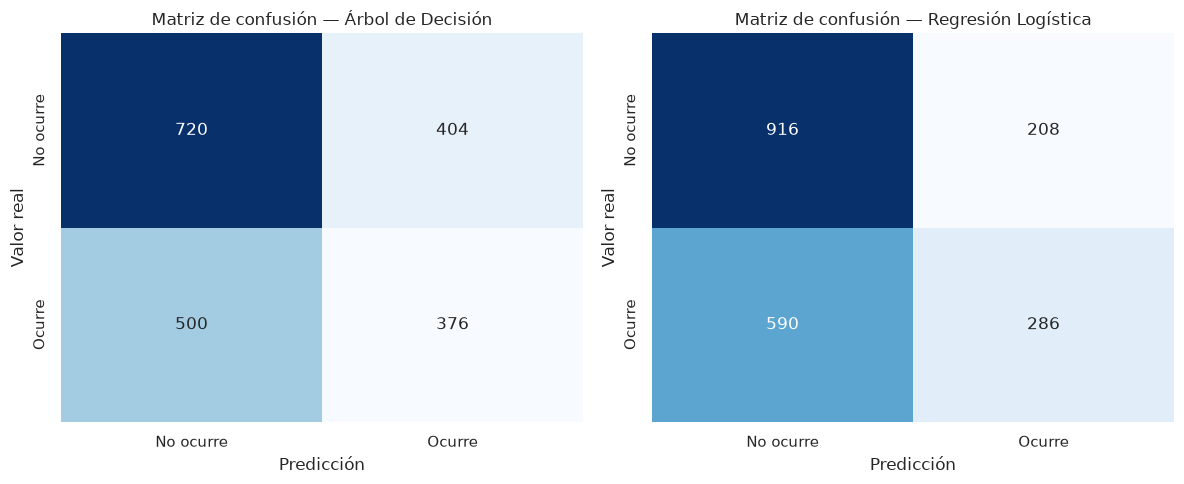

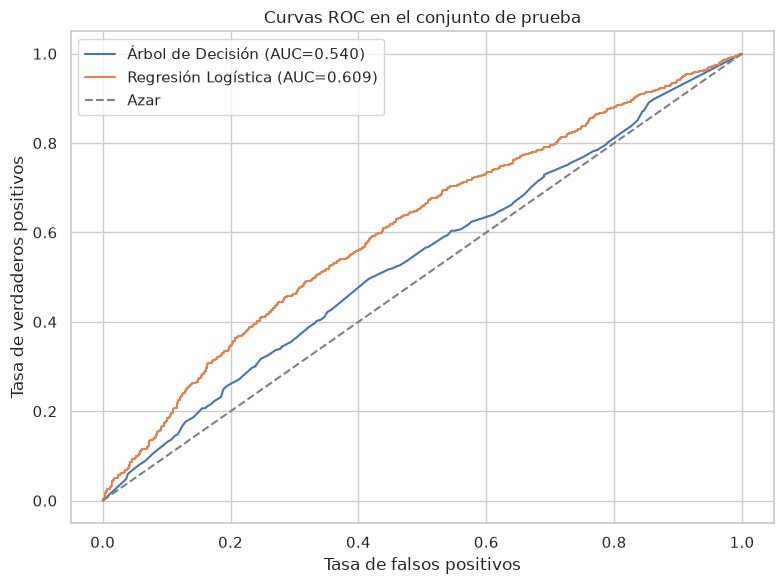

Árbol de Decisión: TN=720, FP=404, FN=500, TP=376; falsos negativos sobre positivos=0.571
Regresión Logística: TN=916, FP=208, FN=590, TP=286; falsos negativos sobre positivos=0.674


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, nombre in zip(axes, modelos):
    cm = confusion_matrix(y_test, predicciones[nombre], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No ocurre', 'Ocurre'], yticklabels=['No ocurre', 'Ocurre'], ax=ax)
    ax.set_title(f'Matriz de confusión — {nombre}')
    ax.set_xlabel('Predicción')
    ax.set_ylabel('Valor real')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for nombre, prob in probabilidades.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f'{nombre} (AUC={roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Azar')
plt.xlabel('Tasa de falsos positivos')
plt.ylabel('Tasa de verdaderos positivos')
plt.title('Curvas ROC en el conjunto de prueba')
plt.legend()
plt.tight_layout()
plt.show()

confusiones = {n: confusion_matrix(y_test, predicciones[n], labels=[0, 1]) for n in modelos}
for nombre, cm in confusiones.items():
    tn, fp, fn, tp = cm.ravel()
    print(f'{nombre}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; falsos negativos sobre positivos={fn/(fn+tp):.3f}')

## 5. Umbrales de decisión

La siguiente tabla muestra el compromiso entre precisión y recall al mover el umbral sobre probabilidades calculadas en el mismo test. No se escoge un umbral con el test para reportarlo como rendimiento final: los valores se presentan como análisis operativo ilustrativo y una decisión real requeriría costos de error definidos y validación independiente.

,modelo,umbral,precision,recall,f1,tasa_alerta
0,Árbol de Decisión,0.2,0.4516,0.7295,0.5578,0.7075
1,Árbol de Decisión,0.3,0.4577,0.6233,0.5278,0.5965
2,Árbol de Decisión,0.4,0.4677,0.5365,0.4997,0.5025
3,Árbol de Decisión,0.5,0.4821,0.4292,0.4541,0.3900
4,Árbol de Decisión,0.6,0.4844,0.3550,0.4097,0.3210
5,Árbol de Decisión,0.7,0.4979,0.2717,0.3516,0.2390
6,Árbol de Decisión,0.8,0.5062,0.1872,0.2733,0.1620
7,Regresión Logística,0.2,0.4380,1.0000,0.6092,1.0000
8,Regresión Logística,0.3,0.4461,0.9589,0.6089,0.9415
9,Regresión Logística,0.4,0.4980,0.7055,0.5838,0.6205


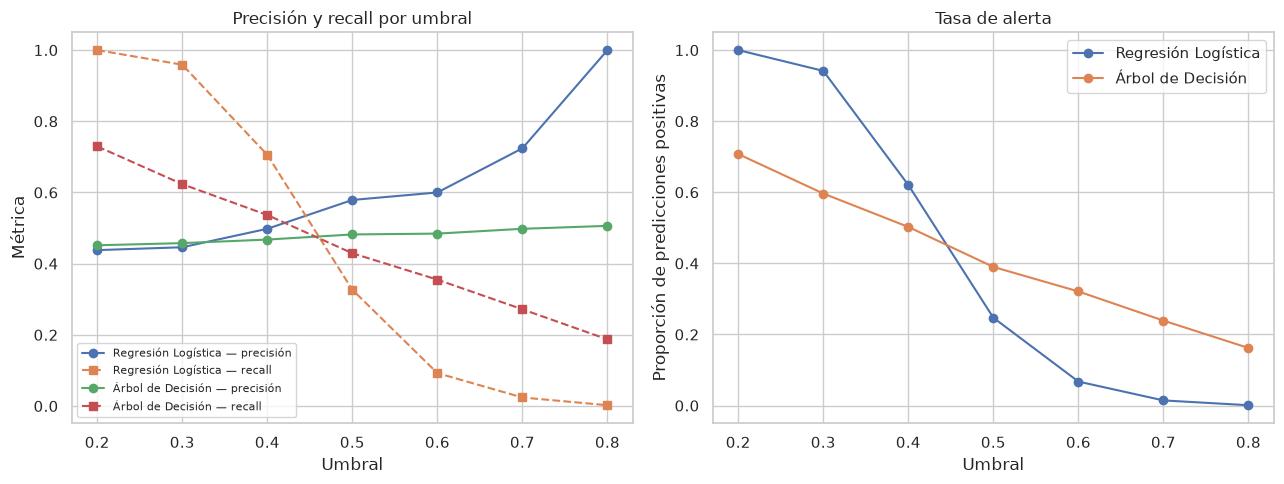

In [8]:
umbrales = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]
filas_umbrales = []
for nombre, prob in probabilidades.items():
    for umbral in umbrales:
        pred = (prob > umbral).astype(int)
        filas_umbrales.append({
            'modelo': nombre, 'umbral': umbral,
            'precision': precision_score(y_test, pred, zero_division=0),
            'recall': recall_score(y_test, pred, zero_division=0),
            'f1': f1_score(y_test, pred, zero_division=0),
            'tasa_alerta': pred.mean()
        })
tabla_umbrales = pd.DataFrame(filas_umbrales)
display(tabla_umbrales.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for nombre, grupo in tabla_umbrales.groupby('modelo'):
    axes[0].plot(grupo.umbral, grupo.precision, marker='o', label=f'{nombre} — precisión')
    axes[0].plot(grupo.umbral, grupo.recall, marker='s', linestyle='--', label=f'{nombre} — recall')
    axes[1].plot(grupo.umbral, grupo.tasa_alerta, marker='o', label=nombre)
axes[0].set(xlabel='Umbral', ylabel='Métrica', title='Precisión y recall por umbral')
axes[0].legend(fontsize=8)
axes[1].set(xlabel='Umbral', ylabel='Proporción de predicciones positivas', title='Tasa de alerta')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Importancia de características y coeficientes

La importancia del árbol es impureza media decreciente y puede favorecer variables con más puntos de corte. Para Regresión Logística se muestran coeficientes en escala estandarizada para variables numéricas y categorías one-hot; el signo describe asociación condicional del modelo, no causalidad.

,importancia
numericas__pendiente_grados,0.1846
numericas__precipitacion_7d_mm,0.1836
numericas__elevacion_m,0.1490
numericas__humedad_pct,0.1477
numericas__precipitacion_3d_mm,0.1288
numericas__precipitacion_24h_mm,0.1269
categoricas__tipo_suelo_Arenoso,0.0141
categoricas__geologia_Ígnea,0.0138
categoricas__departamento_Cochabamba,0.0111
categoricas__tipo_suelo_Franco,0.0100


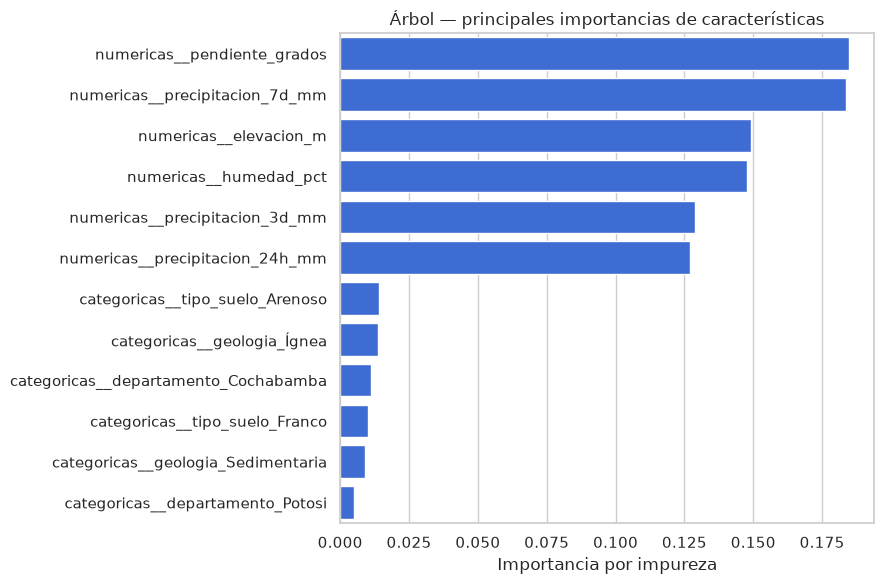

,coeficiente
categoricas__tipo_suelo_Arenoso,-0.1265
categoricas__tipo_suelo_Franco,-0.1136
categoricas__tipo_suelo_Limoso,-0.0970
categoricas__departamento_La Paz,-0.0284
categoricas__departamento_Potosi,-0.0226
numericas__precipitacion_24h_mm,-0.0214
numericas__precipitacion_3d_mm,-0.0103
categoricas__departamento_Cochabamba,-0.0075
categoricas__geologia_Ígnea,-0.0027
numericas__elevacion_m,0.0065


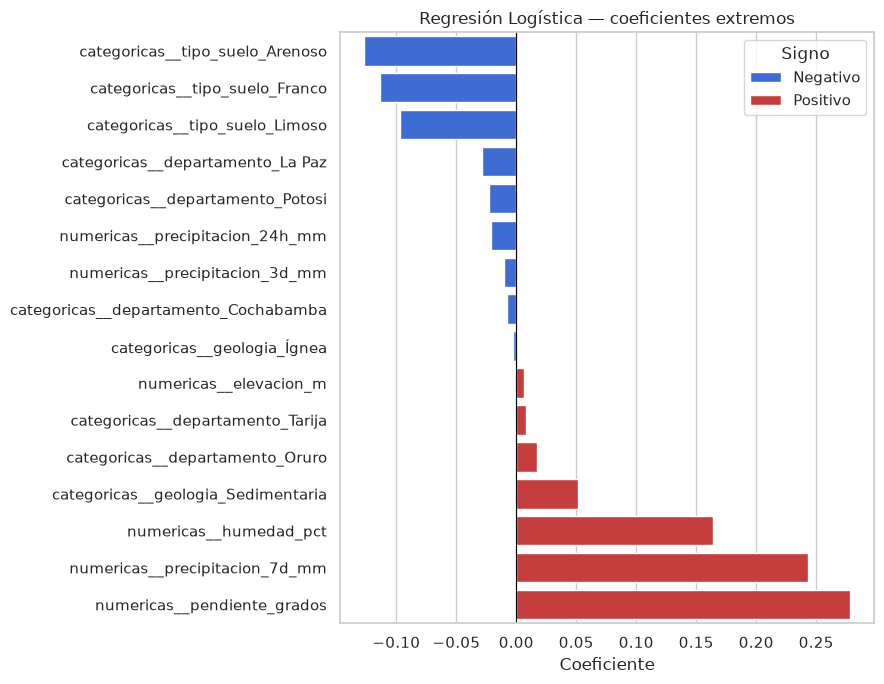

In [9]:
pipeline_arbol = modelos['Árbol de Decisión']
pre_arbol = pipeline_arbol.named_steps['preprocesamiento']
nombres_features = pre_arbol.get_feature_names_out()
importancias = pd.Series(pipeline_arbol.named_steps['modelo'].feature_importances_,
                         index=nombres_features, name='importancia').sort_values(ascending=False)
display(importancias.head(15).to_frame().round(4))
plt.figure(figsize=(9, 6))
sns.barplot(x=importancias.head(12).values, y=importancias.head(12).index, color='#2563eb')
plt.title('Árbol — principales importancias de características')
plt.xlabel('Importancia por impureza')
plt.ylabel('')
plt.tight_layout()
plt.show()

pipeline_lr = modelos['Regresión Logística']
pre_lr = pipeline_lr.named_steps['preprocesamiento']
coeficientes = pd.Series(pipeline_lr.named_steps['modelo'].coef_[0],
                         index=pre_lr.get_feature_names_out(), name='coeficiente').sort_values()
display(pd.concat([coeficientes.head(10), coeficientes.tail(10)]).to_frame().round(4))
coef_plot = pd.concat([coeficientes.head(10), coeficientes.tail(10)])
plt.figure(figsize=(9, 7))
sns.barplot(x=coef_plot.values, y=coef_plot.index,
            hue=np.where(coef_plot.values >= 0, 'Positivo', 'Negativo'),
            palette={'Positivo': '#dc2626', 'Negativo': '#2563eb'}, dodge=False)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Regresión Logística — coeficientes extremos')
plt.xlabel('Coeficiente')
plt.ylabel('')
plt.legend(title='Signo')
plt.tight_layout()
plt.show()

## 7. Sensibilidad a perturbaciones de variables

Se aumenta una variable a la vez en una desviación estándar calculada exclusivamente en train, sin cambiar los valores categóricos ni las otras columnas. Para cada modelo se informa el cambio medio en probabilidad positiva y en proporción de alertas sobre el conjunto test. Esta prueba contrafactual del modelo no estima un efecto causal.

,modelo,variable,incremento aplicado,cambio medio probabilidad,cambio absoluto medio probabilidad,alerta base (%),alerta perturbada (%)
0,Árbol de Decisión,precipitacion_24h_mm,14.7626,-0.0071,0.0961,43.7,44.00
1,Árbol de Decisión,precipitacion_3d_mm,44.2340,-0.0075,0.1032,43.7,42.65
2,Árbol de Decisión,precipitacion_7d_mm,215.2328,0.0781,0.2407,43.7,54.15
3,Árbol de Decisión,pendiente_grados,14.8457,0.0481,0.2712,43.7,52.45
4,Árbol de Decisión,humedad_pct,19.3958,0.0318,0.2041,43.7,48.85
5,Regresión Logística,precipitacion_24h_mm,14.7626,-0.0051,0.0051,24.7,23.40
6,Regresión Logística,precipitacion_3d_mm,44.2340,-0.0024,0.0024,24.7,24.20
7,Regresión Logística,precipitacion_7d_mm,215.2328,0.0581,0.0581,24.7,46.00
8,Regresión Logística,pendiente_grados,14.8457,0.0665,0.0665,24.7,49.75
9,Regresión Logística,humedad_pct,19.3958,0.0391,0.0391,24.7,37.25


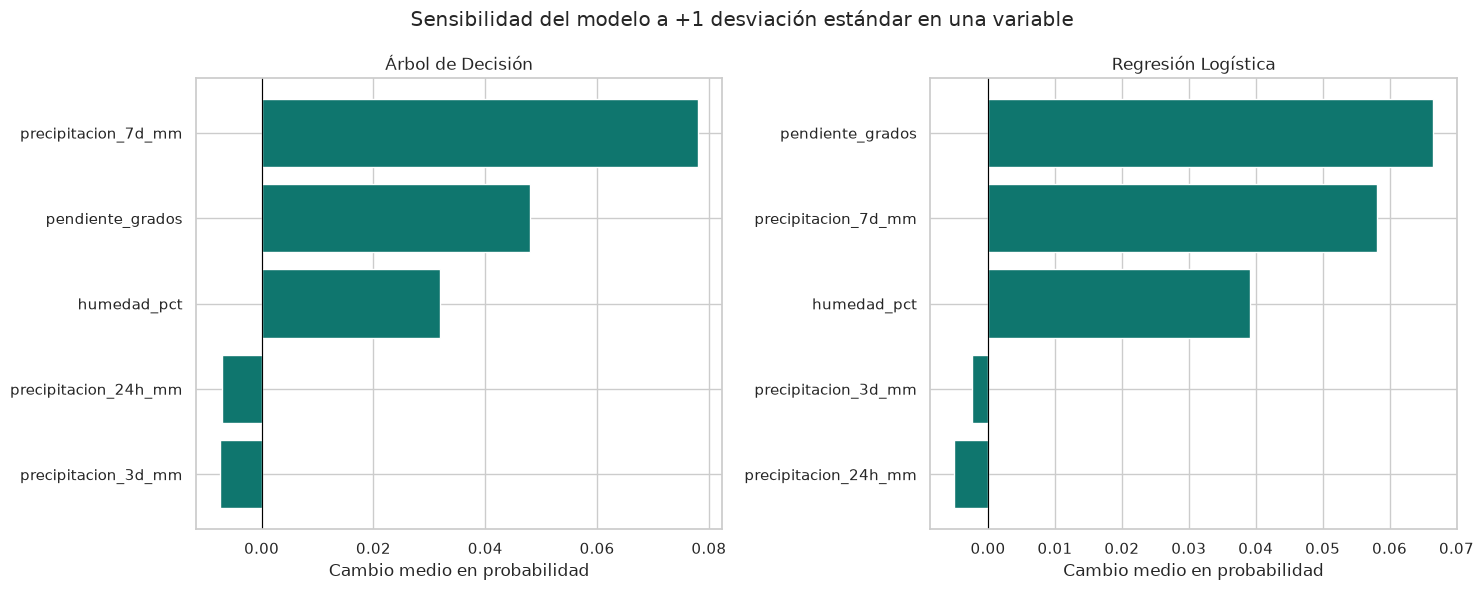

In [10]:
variables_criticas = ['precipitacion_24h_mm', 'precipitacion_3d_mm',
                      'precipitacion_7d_mm', 'pendiente_grados', 'humedad_pct']
filas_sensibilidad = []
for nombre, pipeline in modelos.items():
    prob_base = pipeline.predict_proba(X_test)[:, 1]
    for variable in variables_criticas:
        perturbado = X_test.copy()
        delta = X_train[variable].std(ddof=0)
        perturbado[variable] = perturbado[variable] + delta
        prob_perturbada = pipeline.predict_proba(perturbado)[:, 1]
        filas_sensibilidad.append({
            'modelo': nombre, 'variable': variable,
            'incremento aplicado': delta,
            'cambio medio probabilidad': (prob_perturbada - prob_base).mean(),
            'cambio absoluto medio probabilidad': np.abs(prob_perturbada - prob_base).mean(),
            'alerta base (%)': (prob_base >= 0.5).mean() * 100,
            'alerta perturbada (%)': (prob_perturbada >= 0.5).mean() * 100
        })
tabla_sensibilidad = pd.DataFrame(filas_sensibilidad)
display(tabla_sensibilidad.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (nombre, grupo) in zip(axes, tabla_sensibilidad.groupby('modelo', sort=False)):
    grupo = grupo.sort_values('cambio medio probabilidad')
    ax.barh(grupo.variable, grupo['cambio medio probabilidad'], color='#0f766e')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(nombre)
    ax.set_xlabel('Cambio medio en probabilidad')
plt.suptitle('Sensibilidad del modelo a +1 desviación estándar en una variable')
plt.tight_layout()
plt.show()

## 8. Síntesis y alcance

La tabla de test es la comparación final bajo un split común; la tabla de CV resume estabilidad sobre folds de train. No hay un modelo universalmente preferible sin definir el costo relativo de falsos negativos y falsas alarmas. La etiqueta fue generada probabilísticamente a partir de un score sintético; las métricas miden recuperación de esa regla simulada, no desempeño ante deslizamientos reales.

In [11]:
resumen = tabla_test.copy()
resumen['ROC-AUC CV (media)'] = [resultados_cv[n]['roc_auc'][0] for n in resumen.index]
resumen['ROC-AUC CV (desv.)'] = [resultados_cv[n]['roc_auc'][1] for n in resumen.index]
display(resumen.round(4))
print('Ejecución completada.')
print('Tamaño:', df.shape, '| Nulos:', int(df.isna().sum().sum()),
      '| Duplicados:', int(df.duplicated().sum()))
print('Split estratificado:', len(X_train), 'train /', len(X_test), 'test; semilla:', RANDOM_STATE)
print('Columnas de respuesta excluidas:', VARS_EXCLUIDAS)

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC CV (media),ROC-AUC CV (desv.)
modelo,,,,,,,
Árbol de Decisión,0.548,0.4821,0.4292,0.4541,0.5400,0.5304,0.0092
Regresión Logística,0.601,0.5789,0.3265,0.4175,0.6091,0.6024,0.0076


Ejecución completada.
Tamaño: (10000, 13) | Nulos: 0 | Duplicados: 0
Split estratificado: 8000 train / 2000 test; semilla: 42
Columnas de respuesta excluidas: ['id_registro', 'score_riesgo_bruto', 'indice_riesgo_deslizamiento']
